# The chromatin model: ATAC configurations driving RNA

This notebook shows the **Chromatin** model family: a gene whose nascent and mature RNA
are driven by a locus of binary chromatin sites read out by single-cell ATAC in the same
nucleus (the model of Felce, Gorin and Pachter, 2024, extended to nascent/mature RNA and
to bursty emission). It covers the kernel, the three transcription rules and the two
emissions, building the data from a peak matrix, fitting with `perform_inference`,
comparing rules with `compare_nested_models`, and what a first real dataset taught us.

| Parameter | Symbol | Meaning |
|---|---|---|
| Opening rates | $k_{on,j}$ | One per site, in units of the shared closing rate $k_{off}=1$ |
| Coupling | $\epsilon$ | Neighbouring sites' interaction (1 = independent) |
| Rule rates | $a$ | Nascent transcription rate set by the open sites: `switch` (1 rate), `additive` (1 per site), `table` (1 per configuration) |
| Splicing | $\beta$ | Nascent to mature |
| Degradation | $\gamma$ | Mature RNA |
| Burst size | $b$ | Mean geometric burst size with `bursty=True` (last parameter) |
| ATAC dropout | $p_{drop}$ | An open site read as closed; a sampling parameter on the configuration axis, scanned on the grid |

**Runtime:** a few minutes; the fits in sections 5 and 6 dominate.

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))

In [2]:
import time, tempfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad

from monod import chromatin as ch
from monod import chromatin_fit as cf
from monod import chromatin_data as cd
from monod.cme_toolbox import CMEModel, _HAS_RUST

warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
print(f'Rust backend: {_HAS_RUST}')

Rust backend: True


---
## 1 · The locus and the kernel

A locus of $n$ sites has $2^n$ configurations. Each site opens at its own rate and closes at
rate 1; $\epsilon$ couples neighbours (an Ising-type chain). The configuration sets the nascent
transcription rate through a **rule**, and the RNA then splices and degrades as in the
constitutive model. `nascent_mature_system` returns the three matrices the kernel needs: the
chain generator `H`, the production rates per configuration `A`, and the RNA characteristics `C`.

In [3]:
k_on, k_off, eps = [0.5, 0.8], 1.0, 0.6
configs = ch.configurations(2)                    # rows: (site 0, site 1); site 0 is the least significant bit
pi = ch.ising_steady_state(k_on, k_off, eps)
print('configuration  stationary probability')
for c, p in zip(configs, pi):
    print(f'   {c}        {p:.3f}')

print('\nnascent transcription rate per configuration (00, 10, 01, 11):')
for rule, params in [('switch', [4.0]), ('additive', [3.0, 1.0]), ('table', [0.0, 0.0, 0.0, 4.0])]:
    print(f'  {rule:9s} {params}  ->  {ch.transcription_rates(rule, 2, params)}')

configuration  stationary probability
   [0 0]        0.459
   [1 0]        0.138
   [0 1]        0.220
   [1 1]        0.183

nascent transcription rate per configuration (00, 10, 01, 11):
  switch    [4.0]  ->  [0. 4. 4. 4.]
  additive  [3.0, 1.0]  ->  [0. 3. 1. 4.]
  table     [0.0, 0.0, 0.0, 4.0]  ->  [0. 0. 0. 4.]


`eval_joint_pss` integrates the vector generating function (one component per configuration)
with the exponential integrator and inverts it on the RNA grid. The result is the joint
distribution $P[c, u, s]$ of configuration, nascent and mature counts. The Rust backend
runs when `monod_core` is installed; the NumPy path is the reference.

In [4]:
beta, gamma = 0.8, 0.3
H, A, C = ch.nascent_mature_system(k_on, k_off, eps, 'additive', beta, gamma, rule_params=[3.0, 1.0])
limits = [30, 50]

t0 = time.time(); pss = ch.eval_joint_pss(H, A, C, limits); dt = time.time() - t0
print(f'joint distribution shape {pss.shape} (configuration, nascent, mature), sum {pss.sum():.6f}, {dt*1e3:.0f} ms')
if _HAS_RUST:
    ref = ch.eval_joint_pss(H, A, C, limits, backend='python')
    print(f'Rust vs NumPy max |difference|: {np.abs(pss - ref).max():.2e}')

mu, cov = ch.moments(pss, 2)
print(f'\nmeans: site 0 open {mu[0]:.3f}, site 1 open {mu[1]:.3f}, nascent {mu[2]:.3f}, mature {mu[3]:.3f}')

joint distribution shape (4, 30, 50) (configuration, nascent, mature), sum 1.000000, 103 ms


Rust vs NumPy max |difference|: 2.43e-17

means: site 0 open 0.321, site 1 open 0.404, nascent 1.709, mature 4.557


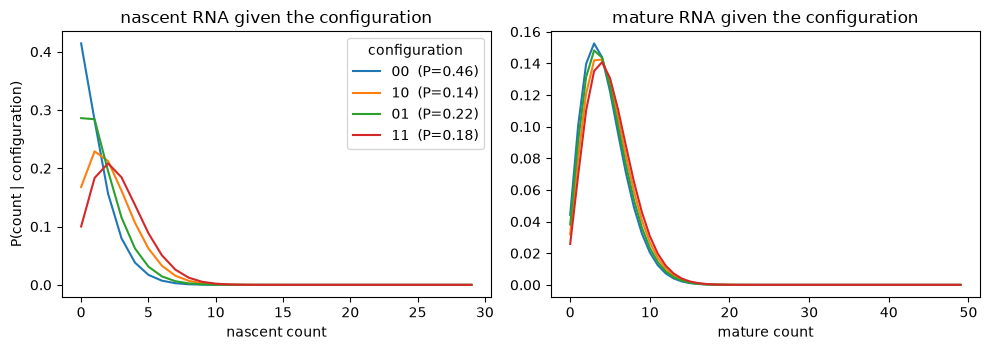

In [5]:
labels = ['00', '10', '01', '11']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for c in range(4):
    cond = pss[c] / pss[c].sum()
    axes[0].plot(cond.sum(1), label=f'{labels[c]}  (P={pss[c].sum():.2f})')
    axes[1].plot(cond.sum(0), label=labels[c])
axes[0].set(xlabel='nascent count', ylabel='P(count | configuration)', title='nascent RNA given the configuration')
axes[1].set(xlabel='mature count', title='mature RNA given the configuration')
axes[0].legend(title='configuration')
plt.tight_layout(); plt.savefig('figures/chromatin_conditional.png', dpi=120); plt.show()

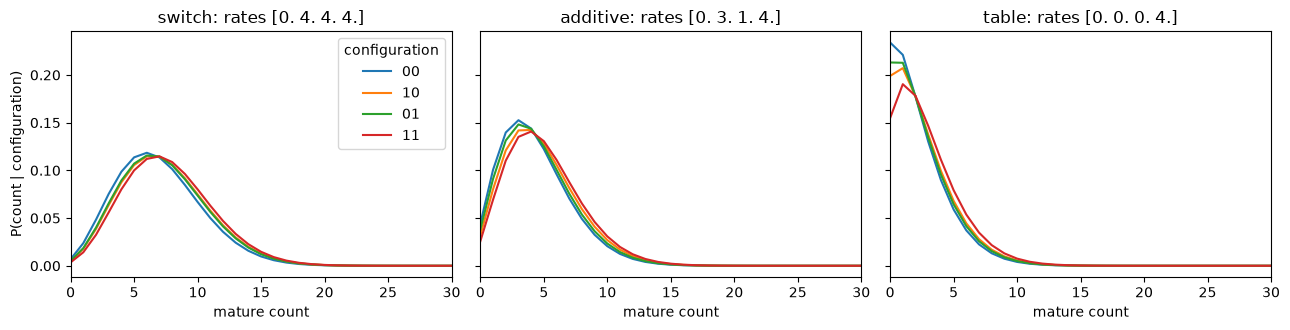

In [6]:
# the same locus under the three rules, at the same total production: P(mature | configuration)
rules = [('switch', [4.0]), ('additive', [3.0, 1.0]), ('table', [0.0, 0.0, 0.0, 4.0])]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (rule, params) in zip(axes, rules):
    Hr, Ar, Cr = ch.nascent_mature_system(k_on, k_off, eps, rule, beta, gamma, rule_params=params)
    Pr = ch.eval_joint_pss(Hr, Ar, Cr, limits)
    for c in range(4):
        ax.plot(Pr[c].sum(0) / Pr[c].sum(), label=labels[c])
    ax.set(title=f'{rule}: rates {ch.transcription_rates(rule, 2, params)}', xlabel='mature count', xlim=(0, 30))
axes[0].set_ylabel('P(count | configuration)'); axes[0].legend(title='configuration')
plt.tight_layout(); plt.savefig('figures/chromatin_rules.png', dpi=120); plt.show()

With $\gamma = 0.3$ the RNA lives about three chromatin dwell times, so the snapshot configuration
still says a lot about the RNA: the additive rule gives four distinct conditional distributions,
the switch collapses the three open configurations onto one curve, and the AND-gate table
separates `11` from everything else. Keep the value of $\gamma$ in mind for section 7.

---
## 2 · Two emissions: single molecules or bursts

By default a configuration transcribes single molecules at its rate. With `burst=b` the emission
is geometric bursts of mean size $b$ while the rule's rates stay **mean** production rates, so
the means are unchanged and the constitutive model is the small-$b$ limit. One always-open site
with bursts is exactly monod's `Bursty` model.

                constitutive   bursts b=3
mean mature         4.557         4.557
Fano mature         1.765         3.946
Fano nascent        1.747         4.697

always-open site with bursts vs CMEModel("Bursty"): max |difference| 4.0e-08


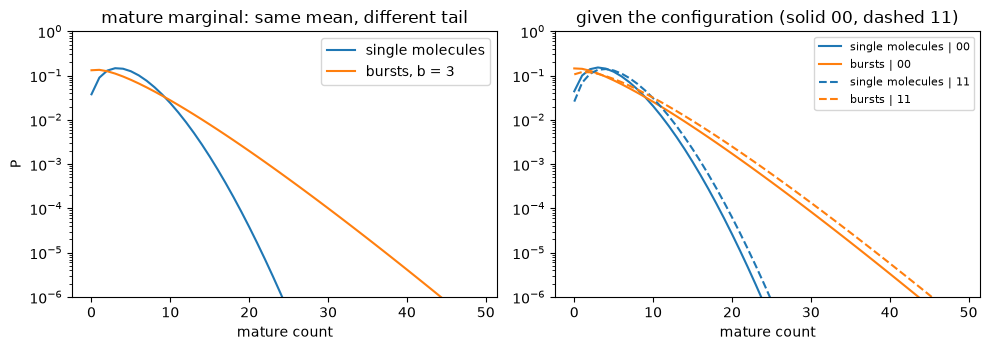

In [7]:
pss_b = ch.eval_joint_pss(H, A, C, limits, burst=3.0)
mu_b, cov_b = ch.moments(pss_b, 2)
print('                constitutive   bursts b=3')
print(f'mean mature      {mu[3]:8.3f}      {mu_b[3]:8.3f}')
print(f'Fano mature      {cov[3, 3] / mu[3]:8.3f}      {cov_b[3, 3] / mu_b[3]:8.3f}')
print(f'Fano nascent     {cov[2, 2] / mu[2]:8.3f}      {cov_b[2, 2] / mu_b[2]:8.3f}')

# one always-open site transcribing bursts of size b at mean rate b: burst frequency 1 = the Bursty model
b = 3.0
H1, A1, C1 = ch.nascent_mature_system([1.0], 1e-9, 1.0, lambda s: b * s.sum(), 0.7, 0.3)
joint = ch.eval_joint_pss(H1, A1, C1, [40, 50], burst=b)
ref = CMEModel('Bursty', 'None').eval_model_pss(np.log10([b, 0.7, 0.3]), [40, 50])
print(f'\nalways-open site with bursts vs CMEModel("Bursty"): max |difference| {np.abs(joint.sum(0) - ref).max():.1e}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].semilogy(pss.sum((0, 1)), label='single molecules')
axes[0].semilogy(pss_b.sum((0, 1)), label='bursts, b = 3')
axes[0].set(xlabel='mature count', ylabel='P', title='mature marginal: same mean, different tail', ylim=(1e-6, 1))
axes[0].legend()
for c, ls in ((0, '-'), (3, '--')):
    axes[1].semilogy(pss[c].sum(0) / pss[c].sum(), ls, color='tab:blue', label=f'single molecules | {labels[c]}')
    axes[1].semilogy(pss_b[c].sum(0) / pss_b[c].sum(), ls, color='tab:orange', label=f'bursts | {labels[c]}')
axes[1].set(xlabel='mature count', title='given the configuration (solid 00, dashed 11)', ylim=(1e-6, 1))
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/chromatin_bursts.png', dpi=120); plt.show()

Bursts widen the distribution in every configuration without moving the curves apart, whereas
a gate moves them apart. In principle the two leave different fingerprints; in practice RNA that
outlives the configuration and ATAC dropout blur the conditional distributions, and section 6
shows that a model with only one of the two mechanisms can reproduce most of what the eye sees
of data made by the other. The likelihood sees the rest.

---
## 3 · The model in `CMEModel`, and the rules as a nested family

`CMEModel("Chromatin", seq_model, n_sites=, rule=, bursty=)` wraps the kernel as an ordinary
model: log10 parameters, bounds, a moments start, dropout on the configuration axis, and the
three modalities `unspliced`, `spliced`, `configuration`. The `table` rule has one free rate
per configuration and nests the other two: `chromatin_fit.embed_in_table` maps a `switch` or
`additive` vector into the table's space (closed configurations at the rate floor), which is
what the nested comparison in section 5 uses as a warm start.

In [8]:
for rule in ('switch', 'additive', 'table'):
    for bursty in (False, True):
        m = CMEModel('Chromatin', 'None', n_sites=2, rule=rule, bursty=bursty)
        print(f'{rule:9s} bursty={bursty!s:5s} {m.get_num_params()} parameters: {m.param_names()}')

theta_sw = cf.join_theta(k_on, eps, [4.0], beta, gamma)                 # log10 vector of the switch model
print('\nswitch vector (log10):', np.round(theta_sw, 3))
print('embedded in the table:', np.round(cf.embed_in_table(theta_sw, 'switch', 2), 3))
k, e, rates, bt, gm = cf.split_theta(cf.embed_in_table(theta_sw, 'switch', 2), 'table', 2)
print('table rates (00, 10, 01, 11) in linear units:', rates)

m_sw = CMEModel('Chromatin', 'None', n_sites=2, rule='switch', dropout_bounds=(0.0, 0.0, 1))
p_model = m_sw.eval_model_pss(theta_sw, [30, 50, 4])                   # (nascent, mature, configuration)
print('\nCMEModel joint distribution shape:', p_model.shape)

switch    bursty=False 6 parameters: ['k_{on,0}', 'k_{on,1}', 'epsilon', 'a', 'beta', 'gamma']
switch    bursty=True  7 parameters: ['k_{on,0}', 'k_{on,1}', 'epsilon', 'a', 'beta', 'gamma', 'b']
additive  bursty=False 7 parameters: ['k_{on,0}', 'k_{on,1}', 'epsilon', 'a_{0}', 'a_{1}', 'beta', 'gamma']
additive  bursty=True  8 parameters: ['k_{on,0}', 'k_{on,1}', 'epsilon', 'a_{0}', 'a_{1}', 'beta', 'gamma', 'b']
table     bursty=False 9 parameters: ['k_{on,0}', 'k_{on,1}', 'epsilon', 'a_{0}', 'a_{1}', 'a_{2}', 'a_{3}', 'beta', 'gamma']
table     bursty=True  10 parameters: ['k_{on,0}', 'k_{on,1}', 'epsilon', 'a_{0}', 'a_{1}', 'a_{2}', 'a_{3}', 'beta', 'gamma', 'b']

switch vector (log10): [-0.301 -0.097 -0.222  0.602 -0.097 -0.523]
embedded in the table: [-0.301 -0.097 -0.222 -4.     0.602  0.602  0.602 -0.097 -0.523]
table rates (00, 10, 01, 11) in linear units: [1.e-04 4.e+00 4.e+00 4.e+00]

CMEModel joint distribution shape: (30, 50, 4)


---
## 4 · Building the data from a peak matrix

`chromatin_data.build_multiome_adata` takes an RNA AnnData with `unspliced` and `spliced`
layers, an ATAC AnnData of fragment counts per peak (coordinates in `var` or in the peak names)
and a gene annotation (a table or a GTF path), assigns peaks to genes by a rule
(`tss_window`, `gene_body` or `loci_promoter`), keeps the `n_sites` peaks nearest the start
site ordered along transcription, binarises them at one fragment, and writes the integer
`configuration` layer. Here on a toy peak set: gene A has three peaks within 1.5 kb of its
TSS, gene B one, gene C none.

In [9]:
rng = np.random.default_rng(0)
n_cells = 300
cells = [f'c{i}' for i in range(n_cells)]
peak_names = ['chr1:9000-9400', 'chr1:9800-10200', 'chr1:10500-10900', 'chr1:2000-2300', 'chr1:15000-15400',
              'chr2:5000-5300', 'chr2:30000-30400']
genes = pd.DataFrame({'gene': ['A', 'B', 'C'], 'chrom': ['chr1', 'chr2', 'chr1'],
                      'start': [10000, 4800, 15200], 'end': [20000, 6000, 15300], 'strand': ['+', '-', '+']})
atac = ad.AnnData(X=rng.poisson(0.6, size=(n_cells, len(peak_names))).astype(float),
                  obs=pd.DataFrame(index=cells), var=pd.DataFrame(index=peak_names))
rna = ad.AnnData(X=np.zeros((n_cells, 3)), obs=pd.DataFrame(index=cells), var=pd.DataFrame(index=['A', 'B', 'C']),
                 layers={'unspliced': rng.poisson(3, size=(n_cells, 3)), 'spliced': rng.poisson(8, size=(n_cells, 3))})

out = cd.build_multiome_adata(rna, atac, genes, rule='tss_window', n_sites=2, window=1500)
print(out)
print('\nsites kept (site 0 is the most upstream):')
print(cd.site_summary(out).to_string(index=False))
print('\nconfiguration counts for gene A (0 = both closed, 3 = both open):',
      np.bincount(np.asarray(out.layers['configuration'][:, 0]), minlength=4))
print('\nassignment with the gene-body rule instead:')
print(cd.assign_peaks(cd.peaks_from_var(atac.var), genes, rule='gene_body', upstream=500)[['gene', 'site', 'peak', 'distance']].to_string(index=False))

AnnData object with n_obs × n_vars = 300 × 1
    uns: 'chromatin_sites', 'chromatin_data'
    layers: 'unspliced', 'spliced', 'configuration'

sites kept (site 0 is the most upstream):
gene  site             peak chrom  start   end  open_fraction
   A     0  chr1:9800-10200  chr1   9800 10200       0.453333
   A     1 chr1:10500-10900  chr1  10500 10900       0.460000

configuration counts for gene A (0 = both closed, 3 = both open): [96 66 68 70]

assignment with the gene-body rule instead:
gene  site             peak  distance
   A     0  chr1:9800-10200         0
   A     1 chr1:10500-10900       500
   A     2 chr1:15000-15400      5000
   B     0   chr2:5000-5300       701
   C     0 chr1:15000-15400         0


---
## 5 · Fitting with `perform_inference`

A synthetic dataset of three genes drawn from the model at a known ATAC dropout of 10 %:

- **geneA**: `switch` rule, single molecules.
- **geneB**: an AND gate, `table` rule with production only when both sites are open.
- **geneC**: `switch` rule with bursts of mean size 3.

All three are fitted with the plain constitutive `switch` model. The dropout is a sampling
parameter, so it is scanned on a three-point grid like a capture rate, and the gene pool runs
on `num_cores` threads.

In [10]:
TRUTH = dict(k_on=[0.5, 0.8], eps=0.6, beta=0.8, gamma=0.3)
p_drop = 0.1
samp_true = [0.0, 0.0, float(np.log10(p_drop))]

def model(rule, bursty=False, grid=(np.log10(p_drop), np.log10(p_drop), 1)):
    return CMEModel('Chromatin', 'None', n_sites=2, rule=rule, bursty=bursty, dropout_bounds=grid)

def draw_cells(m, theta, n, rng, limits=(40, 60, 4)):
    pss = m.eval_model_pss(theta, list(limits), samp_true)
    flat = pss.ravel() / pss.sum()
    idx = rng.choice(flat.size, size=n, p=flat)
    return np.column_stack(np.unravel_index(idx, pss.shape))             # (unspliced, spliced, configuration)

truths = {
    'geneA': ('switch', False, cf.join_theta(TRUTH['k_on'], TRUTH['eps'], [5.0], TRUTH['beta'], TRUTH['gamma'])),
    'geneB': ('table', False, cf.join_theta(TRUTH['k_on'], TRUTH['eps'], [1e-4, 1e-4, 1e-4, 5.0], TRUTH['beta'], TRUTH['gamma'])),
    'geneC': ('switch', True, cf.join_theta(TRUTH['k_on'], TRUTH['eps'], [3.0], TRUTH['beta'], TRUTH['gamma'], burst=3.0)),
}
n_cells = 1500
rng = np.random.default_rng(4)
layers = {k: np.zeros((n_cells, 3), dtype=np.int64) for k in ('unspliced', 'spliced', 'configuration')}
for j, (g, (rule, bursty, theta)) in enumerate(truths.items()):
    c = draw_cells(model(rule, bursty), theta, n_cells, rng)
    layers['unspliced'][:, j], layers['spliced'][:, j], layers['configuration'][:, j] = c.T
sim = ad.AnnData(X=layers['spliced'].astype(float), layers=layers,
                 var=pd.DataFrame(index=list(truths)), obs=pd.DataFrame(index=[f'c{i}' for i in range(n_cells)]))
workdir = tempfile.mkdtemp(prefix='chromatin_demo_')
sim_path = os.path.join(workdir, 'simulated.h5ad')
sim.write_h5ad(sim_path)

print('mean counts per gene and configuration (nascent + mature):')
cfg = layers['configuration']; tot = layers['unspliced'] + layers['spliced']
print(pd.DataFrame({g: [tot[cfg[:, j] == c, j].mean() for c in range(4)] for j, g in enumerate(truths)},
                   index=['00', '10', '01', '11']).round(2).T.to_string())

mean counts per gene and configuration (nascent + mature):
          00     10     01     11
geneA  11.43  13.00  12.70  14.54
geneB   3.36   4.20   4.28   6.31
geneC   6.97   7.62   8.22   8.10


In [11]:
from monod.inference import perform_inference, search_result_from_uns, searchdata_from_adata

m_fit = model('switch', grid=(-1.5, -0.5, 3))                          # dropout scanned at 3 %, 10 %, 32 %
gp = {'num_restarts': 1, 'max_iterations': 150, 'check_identifiability': False}
t0 = time.time()
result = perform_inference(sim_path, m_fit, n_genes=3, seed=1, viz=False, gradient_params=gp,
                           dataset_string=os.path.join(workdir, 'switch_fit'), num_cores=3)
print(f'{(time.time() - t0) / 60:.1f} min')

sr = search_result_from_uns(result.uns['search_result'])
sd = searchdata_from_adata(result)
samp_opt = [float(v) for v in np.asarray(sr.samp_optimum, float)]
print(f'dropout optimum: {10 ** samp_opt[2]:.3f} (truth {p_drop}); summed divergence per grid point:',
      np.round(np.asarray(sr.klds, float).sum(1), 4))

names = m_fit.param_names()
fit = pd.DataFrame(10 ** np.asarray(sr.phys_optimum, float), index=list(result.var_names), columns=names)
truth_A = pd.Series(10 ** truths['geneA'][2], index=names, name='geneA truth')
print('\nfitted switch parameters (linear units) and the truth for geneA:')
print(pd.concat([fit, truth_A.to_frame().T]).round(3).to_string())

Grid scan:   0%|          | 0/3 [00:00<?, ?it/s]

Grid scan:  33%|███▎      | 1/3 [00:09<00:19,  9.66s/it]

Grid scan:  67%|██████▋   | 2/3 [00:21<00:10, 10.75s/it]

Grid scan: 100%|██████████| 3/3 [00:33<00:00, 11.58s/it]

Grid scan: 100%|██████████| 3/3 [00:33<00:00, 11.25s/it]

0.6 min
dropout optimum: 0.032 (truth 0.1); summed divergence per grid point: [1.2541 1.2642 1.3056]

fitted switch parameters (linear units) and the truth for geneA:
             k_{on,0}  k_{on,1}  epsilon      a   beta  gamma
geneA           0.453     0.776    0.638  5.009  0.773  0.297
geneB           0.420     0.713    0.438  5.644  2.168  0.822
geneC           0.415     0.568    0.343  9.035  1.592  0.586
geneA truth     0.500     0.800    0.600  5.000  0.800  0.300


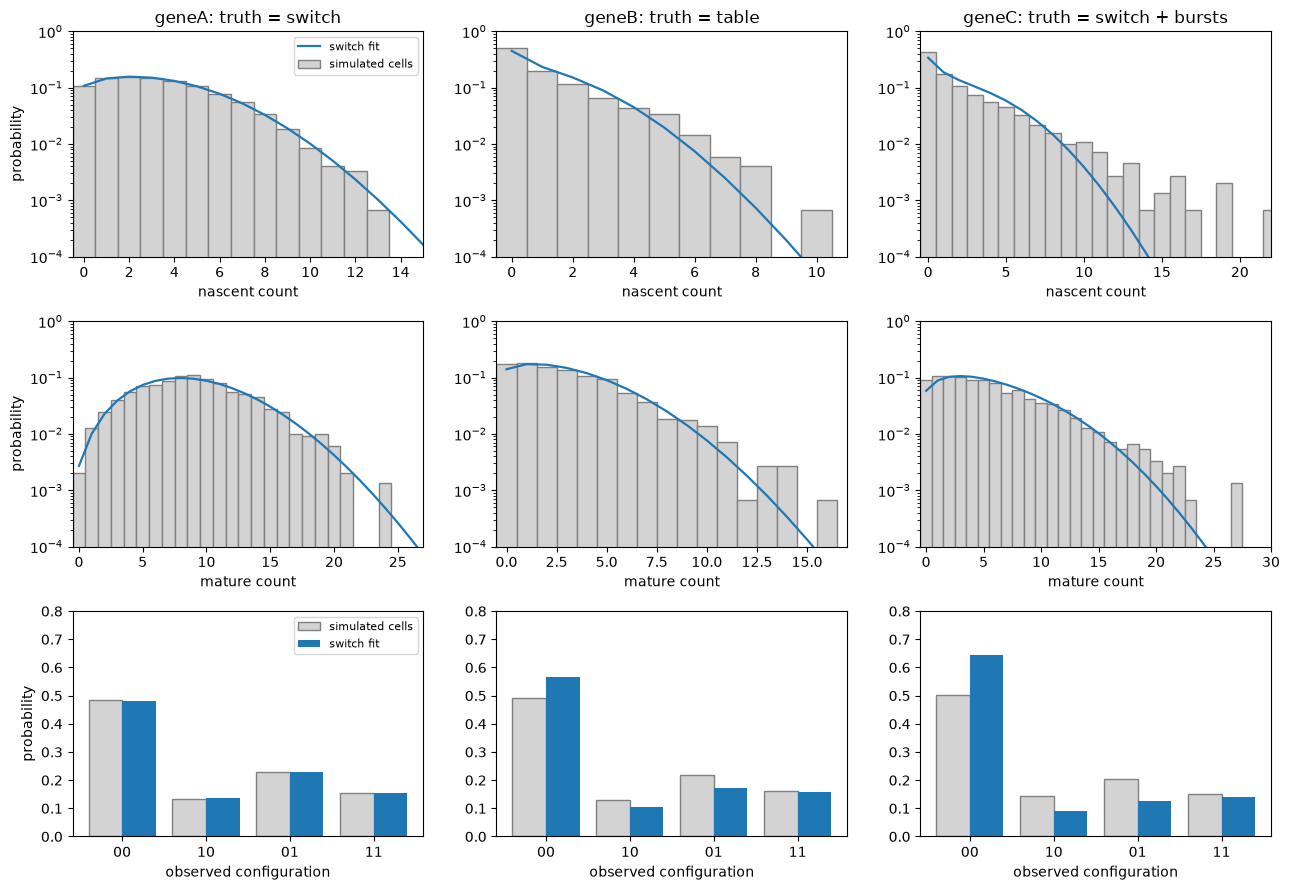

In [12]:
# the fitted switch model against the simulated cells: nascent and mature marginals, and the configuration
X_fit = np.asarray(sr.phys_optimum, float)
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for j, g in enumerate(result.var_names):
    lim_j = sd.M[:, j]
    coords, freqs = sd.hist[j]
    H = np.zeros([int(v) for v in lim_j]); np.add.at(H, tuple(coords.T), freqs)
    P = m_fit.eval_model_pss(X_fit[j], lim_j, samp_opt)
    for row, name in enumerate(('nascent', 'mature')):
        ax = axes[row, j]
        hd = H.sum(axis=(2, 1 - row)); pm = P.sum(axis=(2, 1 - row))
        ax.bar(np.arange(hd.size), hd, color='lightgray', edgecolor='gray', width=1.0, label='simulated cells')
        ax.plot(pm, color='tab:blue', lw=1.6, label='switch fit')
        ax.set(yscale='log', ylim=(1e-4, 1), xlabel=f'{name} count', xlim=(-0.5, np.argmax(np.cumsum(hd) > 0.999) + 3))
        if j == 0: ax.set_ylabel('probability')
    ax = axes[2, j]
    ax.bar(np.arange(4) - 0.2, H.sum(axis=(0, 1)), width=0.4, color='lightgray', edgecolor='gray', label='simulated cells')
    ax.bar(np.arange(4) + 0.2, P.sum(axis=(0, 1)), width=0.4, color='tab:blue', label='switch fit')
    ax.set(xticks=range(4), xticklabels=labels, xlabel='observed configuration', ylim=(0, 0.8))
    axes[0, j].set_title(f"{g}: truth = {truths[g][0]}{' + bursts' if truths[g][1] else ''}")
axes[0, 0].legend(fontsize=8); axes[2, 0].legend(fontsize=8); axes[2, 0].set_ylabel('probability')
plt.tight_layout(); plt.savefig('figures/chromatin_fits.png', dpi=120); plt.show()

geneA comes back within about ten percent of its truth, and its three marginals sit on the data.
For geneB and geneC the switch model is wrong wherever it can bend: it cannot make geneB's rare
high counts from one open-state rate, nor geneC's from single molecules, and in trying it even
distorts the configuration marginal, putting more cells in the all-closed state than are
observed to buy a heavier RNA tail. The dropout is weakly identified by
three genes: the summed divergence differs by a few hundredths across the grid, so the scan may
settle on a neighbouring point and let $k_{on}$ absorb the difference; a real dataset with
thousands of genes pins it down. geneB and geneC are misspecified under the switch rule; the
next section shows how to tell which way.

---
## 6 · Comparing rules and emissions with `compare_nested_models`

`compare_nested_models(small, big, embed, x_small, limits, samp, data, n_cells)` fits the nesting
model warm-started from the small model's optimum (so it can never end worse), in nats, and
reports the likelihood ratio with its chi-square p-value. With `table="score"` a Rao score
test at the embedded point decides whether the big fit is run at all; here the extra
parameters start at a bound where the score test is blind, so `table="always"` fits every
gene. `n_jobs` threads the finite-difference stencil.

Three comparisons per gene: switch to table (is the rule richer than a switch?), constitutive
to bursty switch (are the molecules made in bursts?), and bursty switch to bursty table (does
the rule still gain once bursts are allowed?). The bursty model nests the constitutive one with
$b$ at its floor, so that embedding just appends the floor; `embed_in_table` carries $b$ along.

In [13]:
from monod.analysis import compare_nested_models

small = model('switch', grid=(samp_opt[2], samp_opt[2], 1))
table = model('table', grid=(samp_opt[2], samp_opt[2], 1))
bursty = model('switch', bursty=True, grid=(samp_opt[2], samp_opt[2], 1))
table_bursty = model('table', bursty=True, grid=(samp_opt[2], samp_opt[2], 1))
b_floor = bursty.bio_bounds['phys_lb'][-1]
embed = lambda x: cf.embed_in_table(x, 'switch', 2)

rows = []
t0 = time.time()
for j, g in enumerate(result.var_names):
    x_sw = np.asarray(sr.phys_optimum, float)[j]
    lim, data = sd.M[:, j], sd.hist[j]
    kw = dict(table='always', n_jobs=4)
    r_tab = compare_nested_models(small, table, embed, x_sw, lim, samp_opt, data, sd.n_cells, **kw)
    r_bur = compare_nested_models(small, bursty, lambda x: np.append(x, b_floor), x_sw, lim, samp_opt, data, sd.n_cells, **kw)
    r_both = compare_nested_models(bursty, table_bursty, embed, r_bur['x_big'], lim, samp_opt, data, sd.n_cells, **kw)
    rates = cf.split_theta(r_tab['x_big'], 'table', 2)[2]
    rows.append({'gene': g, 'truth': f"{truths[g][0]}{' + bursts' if truths[g][1] else ''}",
                 'switch->table': r_tab['lr'], 'table rates 00,10,01,11': ' '.join(f'{v:.2g}' for v in rates),
                 'switch->bursty': r_bur['lr'], 'b': cf.burst_size(r_bur['x_big'], 'switch', 2),
                 'bursty switch->bursty table': r_both['lr'], 'p': r_both['p_lr']})
    fits_kept = globals().setdefault('fits_kept', {})
    fits_kept[g] = dict(switch=x_sw, table=r_tab['x_big'], bursty=r_bur['x_big'], bursty_table=r_both['x_big'])
print(f'{(time.time() - t0) / 60:.1f} min')
print('likelihood ratios in nats; chi-square critical values at 5 %: 7.8 (3 df), 3.8 (1 df)')
pd.DataFrame(rows).set_index('gene').round(3)

7.2 min
likelihood ratios in nats; chi-square critical values at 5 %: 7.8 (3 df), 3.8 (1 df)


,truth,switch->table,"table rates 00,10,01,11",switch->bursty,b,bursty switch->bursty table,p
gene,,,,,,,
geneA,switch,0.622,0.0001 5 5.4 4.9,0.000,0.001,0.626,0.891
geneB,table,298.696,0.0001 0.0001 0.16 5,220.049,0.979,78.630,0.000
geneC,switch + bursts,793.481,0.0001 0.0001 0.0001 7.8,1026.147,3.331,1.691,0.639


geneA rejects everything. The other two genes are confounded in **both** of the first two
columns: the constitutive table gains hugely on the bursty geneC, by moving all production
into the rarest configuration (an AND gate that is not there), and the bursty switch gains on
the AND-gate geneB, because transcribing from a rare state looks like bursting. A constitutive
emission has only one way to make an overdispersed RNA distribution, and a switch rule has
only one way to make a rare production state. The last column settles it: once bursts are
allowed, the table still gains on geneB (a real gate) and gains nothing on geneC (bursts).
That 2 by 2 of rule and emission is what the real data needed too.

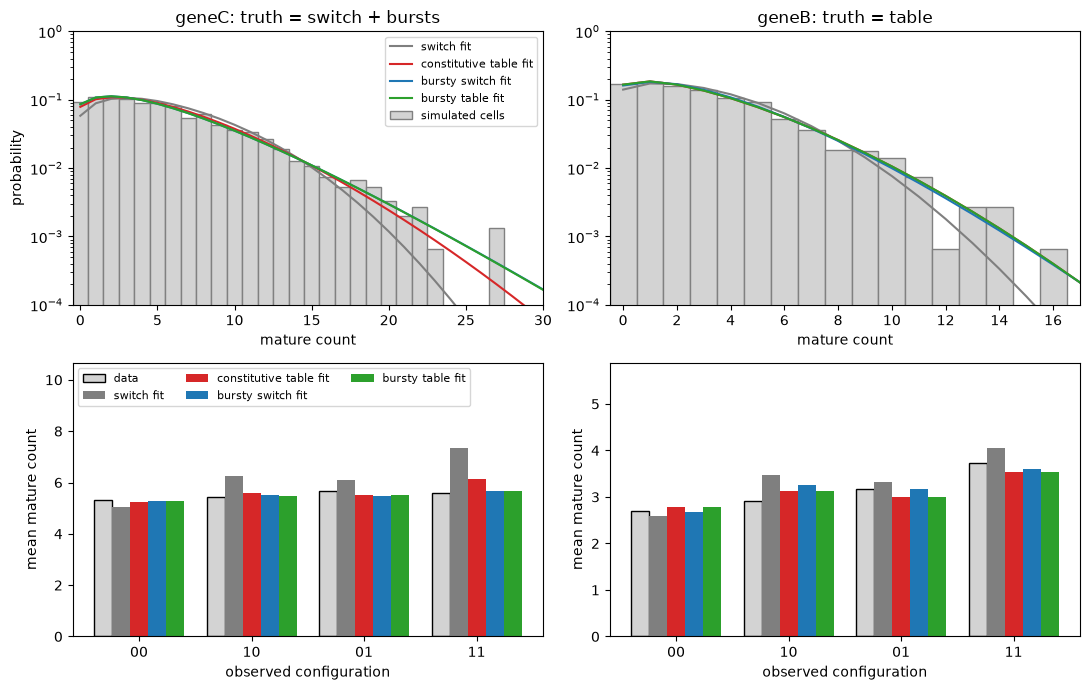

In [14]:
# how the two wrong models explain geneC's bursts: the mature marginal and the mean RNA per configuration
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, g in enumerate(('geneC', 'geneB')):
    j = list(result.var_names).index(g)
    lim_j = sd.M[:, j]
    coords, freqs = sd.hist[j]
    H = np.zeros([int(v) for v in lim_j]); np.add.at(H, tuple(coords.T), freqs)
    models_g = [(small, fits_kept[g]['switch'], 'switch fit', 'tab:gray'),
                (table, fits_kept[g]['table'], 'constitutive table fit', 'tab:red'),
                (bursty, fits_kept[g]['bursty'], 'bursty switch fit', 'tab:blue'),
                (table_bursty, fits_kept[g]['bursty_table'], 'bursty table fit', 'tab:green')]
    ax = axes[0, col]
    hd = H.sum(axis=(0, 2))
    ax.bar(np.arange(hd.size), hd, color='lightgray', edgecolor='gray', width=1.0, label='simulated cells')
    means = {'data': [H[:, :, c].sum(0) @ np.arange(H.shape[1]) / H[:, :, c].sum() for c in range(4)]}
    for m_, x_, lab, c_ in models_g:
        P = m_.eval_model_pss(x_, lim_j, samp_opt)
        ax.plot(P.sum(axis=(0, 2)), color=c_, lw=1.5, label=lab)
        means[lab] = [P[:, :, c].sum(0) @ np.arange(P.shape[1]) / P[:, :, c].sum() for c in range(4)]
    ax.set(yscale='log', ylim=(1e-4, 1), xlabel='mature count', xlim=(-0.5, np.argmax(np.cumsum(hd) > 0.999) + 3),
           title=f"{g}: truth = {truths[g][0]}{' + bursts' if truths[g][1] else ''}")
    if col == 0: ax.set_ylabel('probability'); ax.legend(fontsize=8)
    ax = axes[1, col]
    w = 0.16
    for k_, (lab, mu) in enumerate(means.items()):
        ax.bar(np.arange(4) + (k_ - 2) * w, mu, width=w, label=lab,
               color=['lightgray', 'tab:gray', 'tab:red', 'tab:blue', 'tab:green'][k_], edgecolor='k' if k_ == 0 else None)
    ax.set(xticks=range(4), xticklabels=labels, xlabel='observed configuration', ylabel='mean mature count',
           ylim=(0, 1.45 * max(max(v) for v in means.values())))
    if col == 0: ax.legend(fontsize=8, ncol=3, loc='upper left')
plt.tight_layout(); plt.savefig('figures/chromatin_gate_vs_burst.png', dpi=120); plt.show()

Every model with a free mechanism reproduces the mature marginal, and all of them, the
constitutive table included, reproduce the mean RNA per observed configuration. On geneC the
table does this with production in `11` alone, because it also makes the RNA long-lived, so
each cell's count averages over many configurations and the conditional means stay flat; on
geneB the bursty switch matches the rising means through the dropout-mixed `any open` state.
Neither the marginal nor the conditional means separate a gate from bursts here. What does is
how the tail is shared out across configurations, which is what the likelihood sees and the
nested tests above measure.

---
## 7 · What a first real dataset taught us

CD14+ monocytes from the NeurIPS 2021 BMMC multiome (GSE194122), nascent and mature counts
requantified with `kb count --workflow nac`, two ATAC peaks per gene within 5 kb of the TSS.
On ten genes the constitutive `table` beat the `additive` rule on nine, always as an AND gate.
The gain survived ATAC-depth tertiles, so it was not a depth artefact. Adding bursts changed
the reading entirely:

| Gene | Table over additive, constitutive (nats) | Burst gain, additive (nats) | Fitted b | Table over additive, bursty (nats) |
|---|---|---|---|---|
| CAMK2D | 1035 | 1324 | 2.6 | 0 |
| CEP135 | 354 | 455 | 0.44 | 0 |
| ATP10D | 301 | 316 | 0.37 | 3.5 |
| HNRNPL | 45 | 176 | 0.24 | 0.1 |

With bursty emission the three rules were indistinguishable on every gene, including eighteen
immediate-early genes with fast RNA turnover fitted within single batches. The fitted
$\gamma$ sat near 0.02 in units of $k_{off}$, so the RNA outlives the configuration by tens
of dwell times, and the two-site configuration explained under 3 % of the RNA variance for
all 28 genes. Compare section 1, where $\gamma = 0.3$ gave four clearly different conditional
distributions. The lesson for a new dataset: check the mean RNA per configuration first, fit
the rules with and without bursts, and read a gate only when it survives the burst
comparison.

---
## Summary

- `chromatin.nascent_mature_system` and `eval_joint_pss` give the joint distribution of configuration and RNA for any rule, constitutive or bursty, Rust-accelerated.
- `chromatin_data.build_multiome_adata` turns a peak matrix, RNA layers and a gene annotation into the three-layer AnnData the model fits.
- `CMEModel("Chromatin", ...)` runs through `perform_inference` like any model, with ATAC dropout scanned as a sampling parameter and gene-level threads via `num_cores`.
- `analysis.compare_nested_models` compares rules (via `embed_in_table`) and emissions (append the burst floor) on a gene, warm-started and in nats.
- On the first real dataset, apparent AND gates were burst kinetics; test both before reading regulation into a rule.